# Oscar 1927–2026: dez perguntas estratégicas

Este notebook consome o pacote `projeto1_c11`. A lógica de cada pergunta vive em `src/projeto1_c11/questions/`; aqui entram a narrativa, as tabelas e os gráficos.

**Parte I** (Q1–Q5) é o pitch de 10 minutos. **Parte II** (Q6–Q10) completa as dez perguntas da [`Proposta.md`](../Proposta.md).

Dataset: [`unanimad/the-oscar-award`](https://www.kaggle.com/datasets/unanimad/the-oscar-award).


## 0. Carga e descoberta

In [1]:
from projeto1_c11.data import load_oscars
from projeto1_c11.plotting import apply_style, save_fig
from projeto1_c11.questions import (
    q01_conversao,
    q02_precursoras,
    q03_evolucao,
    q04_eficiencia,
    q05_concentracao,
    q06_persistencia,
    q07_atuacao,
    q08_nomenclatura,
    q09_elegibilidade,
    q10_concorrentes,
)

apply_style()
df = load_oscars()
df.head()


,year_film,year_ceremony,ceremony,category,canon_category,name,film,winner,category_canon,is_best_picture,is_honorary,decade
0,1927,1928,1,ACTOR,ACTOR IN A LEADING ROLE,Richard Barthelmess,The Noose,False,ACTOR IN A LEADING ROLE,False,False,1920
1,1927,1928,1,ACTOR,ACTOR IN A LEADING ROLE,Richard Barthelmess,The Patent Leather Kid,False,ACTOR IN A LEADING ROLE,False,False,1920
2,1927,1928,1,ACTOR,ACTOR IN A LEADING ROLE,Emil Jannings,The Last Command,True,ACTOR IN A LEADING ROLE,False,False,1920
3,1927,1928,1,ACTOR,ACTOR IN A LEADING ROLE,Emil Jannings,The Way of All Flesh,True,ACTOR IN A LEADING ROLE,False,False,1920
4,1927,1928,1,ACTRESS,ACTRESS IN A LEADING ROLE,Louise Dresser,A Ship Comes In,False,ACTRESS IN A LEADING ROLE,False,False,1920


In [2]:
print(f'linhas={len(df):,}  colunas={df.shape[1]}')
print(df.dtypes)
df.isna().sum().to_frame('n_ausentes')

linhas=11,240  colunas=12
year_film            int64
year_ceremony        int64
ceremony             int64
category            string
canon_category         str
name                string
film                string
winner                bool
category_canon      string
is_best_picture    boolean
is_honorary           bool
decade               int64
dtype: object


,n_ausentes
year_film,0
year_ceremony,0
ceremony,0
category,0
canon_category,0
name,12
film,363
winner,0
category_canon,0
is_best_picture,0


In [3]:
n_raw = df['category'].nunique()
n_canon = df['category_canon'].nunique()
print(f'categorias originais={n_raw}  após unificar Melhor Filme={n_canon}')

remakes = (
    df.dropna(subset=['film'])
    .groupby('film')['year_ceremony']
    .nunique()
    .loc[lambda s: s > 1]
    .sort_values(ascending=False)
)
print(f'títulos em mais de uma cerimônia={len(remakes)}')
remakes.head(10).to_frame('n_cerimonias')

categorias originais=120  após unificar Melhor Filme=59
títulos em mais de uma cerimônia=111


,n_cerimonias
film,
A Star Is Born,4
Little Women,4
Emma,3
Hamlet,3
Alice in Wonderland,2
A Farewell to Arms,2
A Place in the Sun,2
Back Street,2
Beauty and the Beast,2


### Três desafios da etapa de Descoberta (Slide 4)

1. **Padronização de categorias históricas.** Melhor Filme já se chamou *Outstanding Picture*, *Outstanding Production*, *Outstanding Motion Picture* e *Best Motion Picture*. Sem unificar esses nomes, qualquer análise da categoria principal parte o século no meio.
2. **Valores ausentes.** Prêmios honorários e especiais frequentemente vêm sem `film` (e às vezes sem `name` padronizado). Por isso as perguntas de filme/profissional excluem `is_honorary` e descartam nulos da chave.
3. **Filmes homônimos.** Remakes compartilham o título; a chave de filme é sempre `['film', 'year_ceremony']`, nunca só o nome.

## Parte I — Cinco perguntas do pitch

## Q1. Volume de indicações e conversão em vitórias

Qual é a relação entre o volume de indicações de um filme e sua taxa de conversão em vitórias? Existe um ponto de virada?

**Como lemos:** cada ponto é um filme-cerimônia. O painel da direita mostra a taxa média de vitória por faixa de indicações — o candidato a "ponto de virada" para o investimento em campanha FYC.

In [4]:
print(q01_conversao.QUESTION)
q01 = q01_conversao.compute(df)
display(q01_conversao.correlations(q01).to_frame('correlação'))
display(q01_conversao.conversion_by_bin(q01))
q01.head(10)

Qual é a relação entre o volume de indicações de um filme e sua taxa de conversão em vitórias? Existe um ponto de virada?


,correlação
pearson,0.689795
spearman,0.433211


,nomination_bin,n_films,mean_wins,mean_win_rate
0,1,3543,0.158905,0.158905
1,2–3,903,0.301218,0.128092
2,4–6,501,0.938124,0.193114
3,7–9,207,2.154589,0.275372
4,10+,107,4.261682,0.380712


,film,year_ceremony,nominations,wins,year_film,win_rate
0,Titanic,1998,14,11,1997,0.785714
1,Ben-Hur,1960,12,11,1959,0.916667
2,The Lord of the Rings: The Return of the King,2004,11,11,2003,1.000000
3,West Side Story,1962,11,10,1961,0.909091
4,The English Patient,1997,12,9,1996,0.750000
5,Gigi,1959,9,9,1958,1.000000
6,The Last Emperor,1988,9,9,1987,1.000000
7,From Here to Eternity,1954,13,8,1953,0.615385
8,Gone with the Wind,1940,13,8,1939,0.615385
9,My Fair Lady,1965,12,8,1964,0.666667


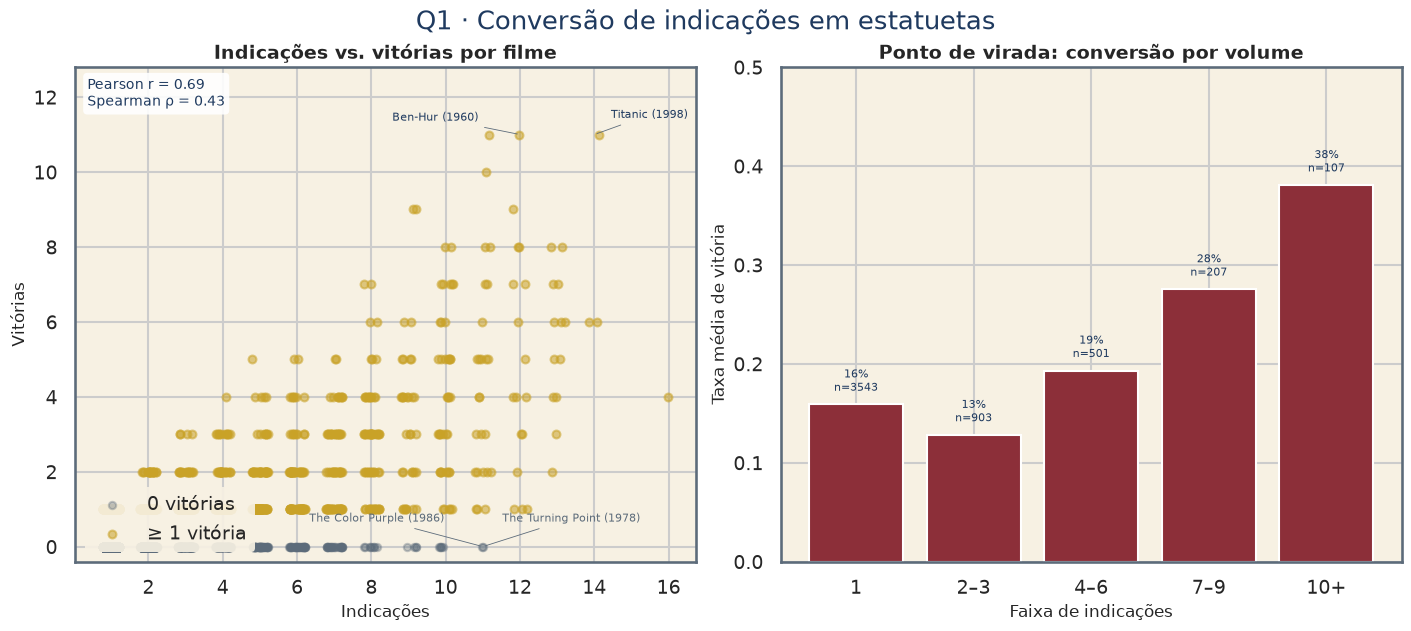

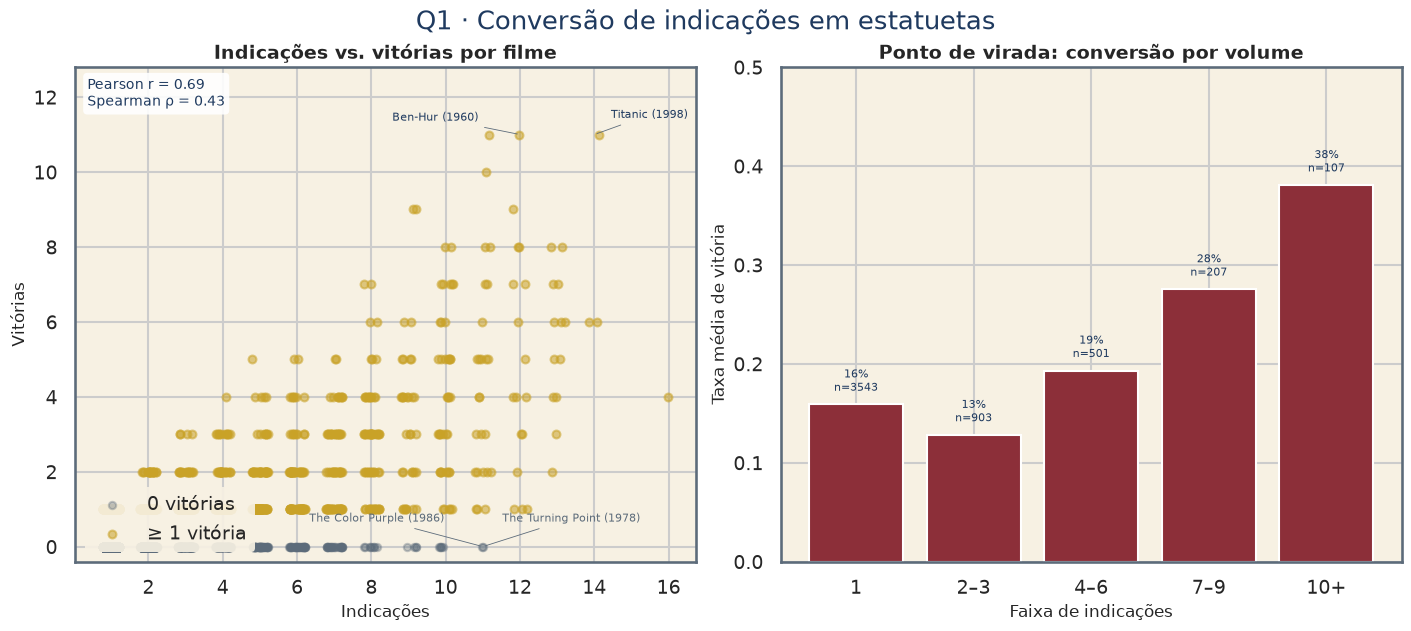

In [5]:
fig = q01_conversao.plot(q01)
save_fig(fig, q01_conversao.SLUG)
fig

**Insight.** Mais indicações acompanham mais vitórias (correlação positiva), mas a conversão não é linear: o salto de faixa costuma aparecer nas faixas altas, enquanto o extremo direito também concentra os maiores esnobados (muitas indicações e zero estatuetas). Para o estúdio, pulverizar campanha em dezenas de categorias não garante a noite — e pode produzir o pior dos mundos: visibilidade máxima sem a foto da estatueta.

## Q2. Categorias precursoras de Melhor Filme

Para um filme vencer Melhor Filme, quais outras categorias historicamente têm a maior correlação de vitória conjunta?

Universo: filmes **indicados** a Melhor Filme (não a indústria inteira). Para cada categoria X: `P(venceu X | venceu BP)`, `P(venceu BP | venceu X)` e o coeficiente φ entre as duas binárias.

In [6]:
print(q02_precursoras.QUESTION)
q02 = q02_precursoras.compute(df)
q02.head(15)

Para um filme vencer Melhor Filme, quais outras categorias historicamente têm a maior correlação de vitória conjunta?


,category,n_films,n_bp_winners,n_won_x,n_won_both,p_x_given_bp,p_bp_given_x,phi
0,DIRECTING,621,98,96,71,0.724490,0.739583,0.682398
1,WRITING (ADAPTED SCREENPLAY),621,98,95,44,0.448980,0.463158,0.355952
2,FILM EDITING,621,98,78,38,0.387755,0.487179,0.342420
3,ACTOR IN A LEADING ROLE,621,98,78,28,0.285714,0.358974,0.209135
4,SOUND MIXING,621,98,53,21,0.214286,0.396226,0.199769
5,ACTOR IN A SUPPORTING ROLE,621,98,53,21,0.214286,0.396226,0.199769
6,CINEMATOGRAPHY (COLOR),621,98,17,9,0.091837,0.529412,0.171006
7,ART DIRECTION,621,98,55,19,0.193878,0.345455,0.160449
8,WRITING (ORIGINAL SCREENPLAY),621,98,60,20,0.204082,0.333333,0.157455
9,COSTUME DESIGN,621,98,33,13,0.132653,0.393939,0.153443


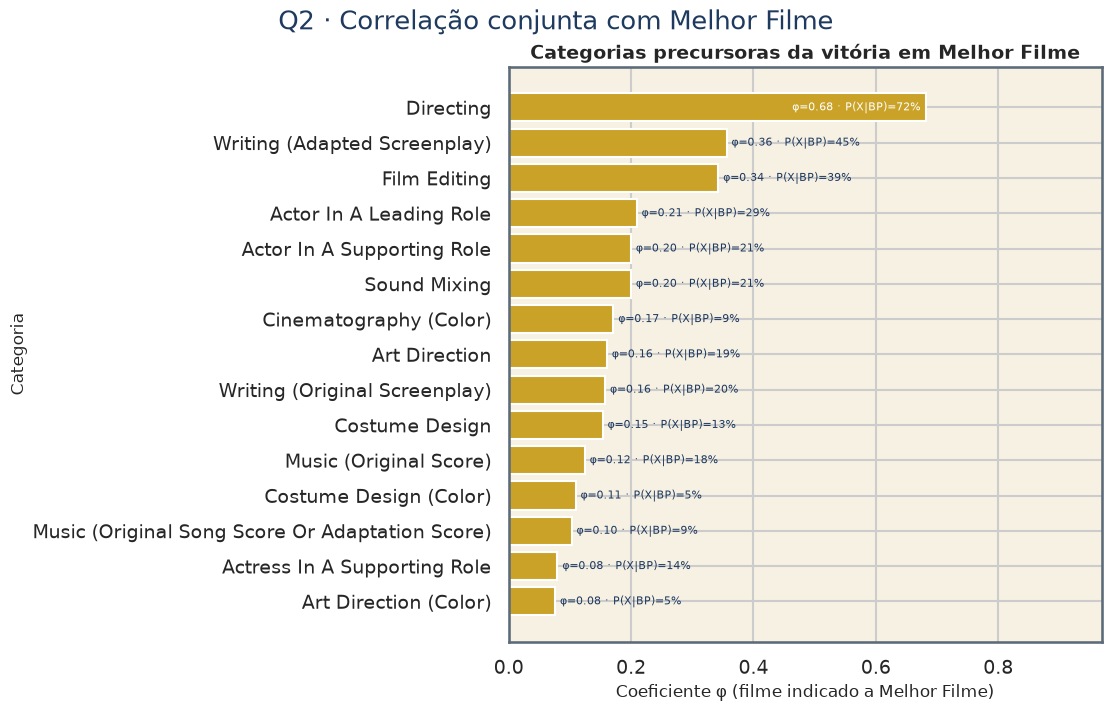

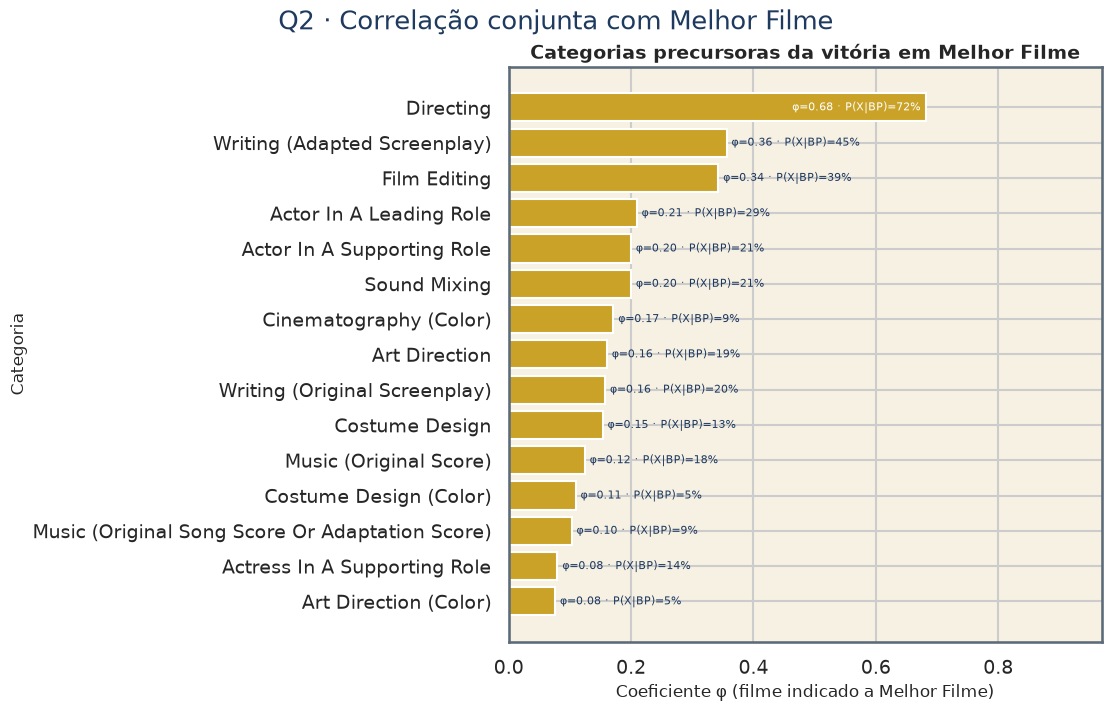

In [7]:
fig = q02_precursoras.plot(q02)
save_fig(fig, q02_precursoras.SLUG)
fig

**Insight.** Direção, montagem e roteiro original/adaptado costumam ser o termômetro real da noite: um filme que leva essas categorias raramente é só "indicado de volume". Produtoras e apostadores devem tratar essas estatuetas como precursoras, não como prêmios consolação.

## Q3. Evolução da Academia por década

Como o perfil da Academia evoluiu ao longo das décadas em termos de diversidade de categorias e quantidade de prêmios distribuídos por cerimônia?

In [8]:
print(q03_evolucao.QUESTION)
q03 = q03_evolucao.compute(df)
q03

Como o perfil da Academia evoluiu ao longo das décadas em termos de diversidade de categorias e quantidade de prêmios distribuídos por cerimônia?


,decade,n_categories,n_categories_canon,n_nominations,n_wins,n_ceremonies,wins_per_ceremony,nominations_per_ceremony
0,1920,15,14,87,25,2,12.500000,43.500000
1,1930,27,25,718,158,9,17.555556,79.777778
2,1940,38,30,1502,277,10,27.700000,150.200000
3,1950,43,37,1188,294,10,29.400000,118.800000
4,1960,40,32,1195,278,10,27.800000,119.500000
5,1970,51,30,1061,257,10,25.700000,106.100000
6,1980,36,33,1072,267,10,26.700000,107.200000
7,1990,35,33,1135,280,10,28.000000,113.500000
8,2000,34,30,1147,282,10,28.200000,114.700000
9,2010,33,31,1260,290,10,29.000000,126.000000


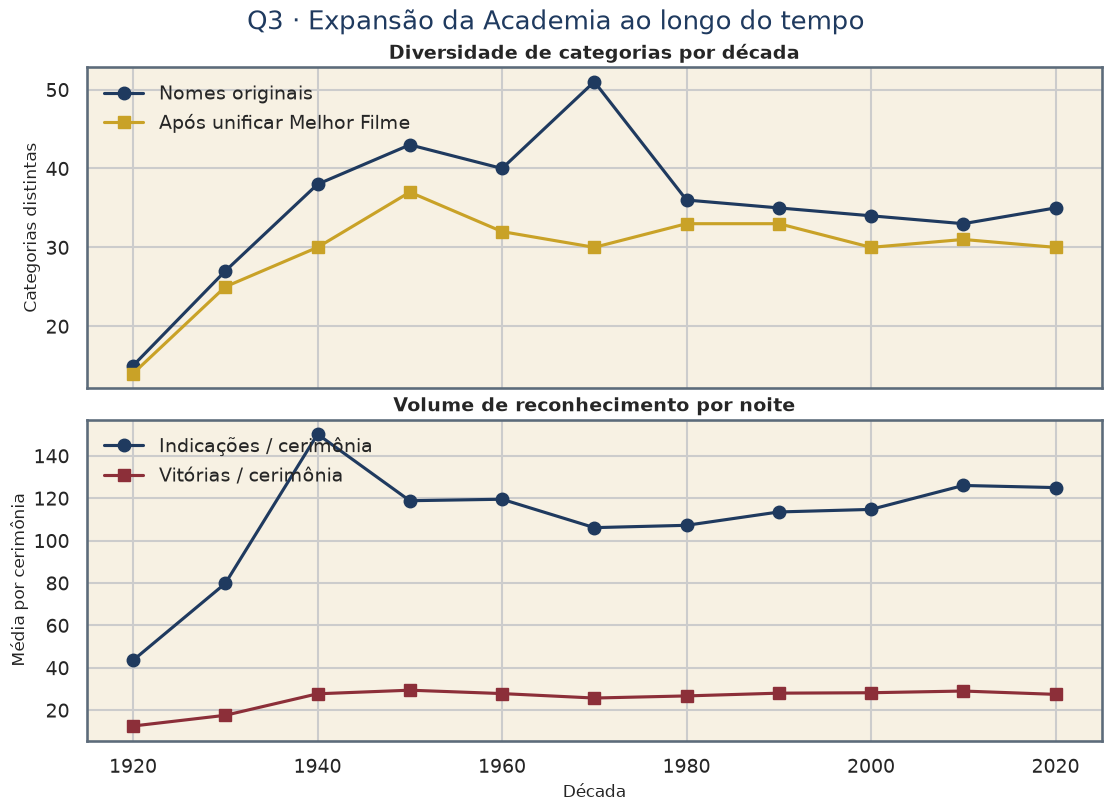

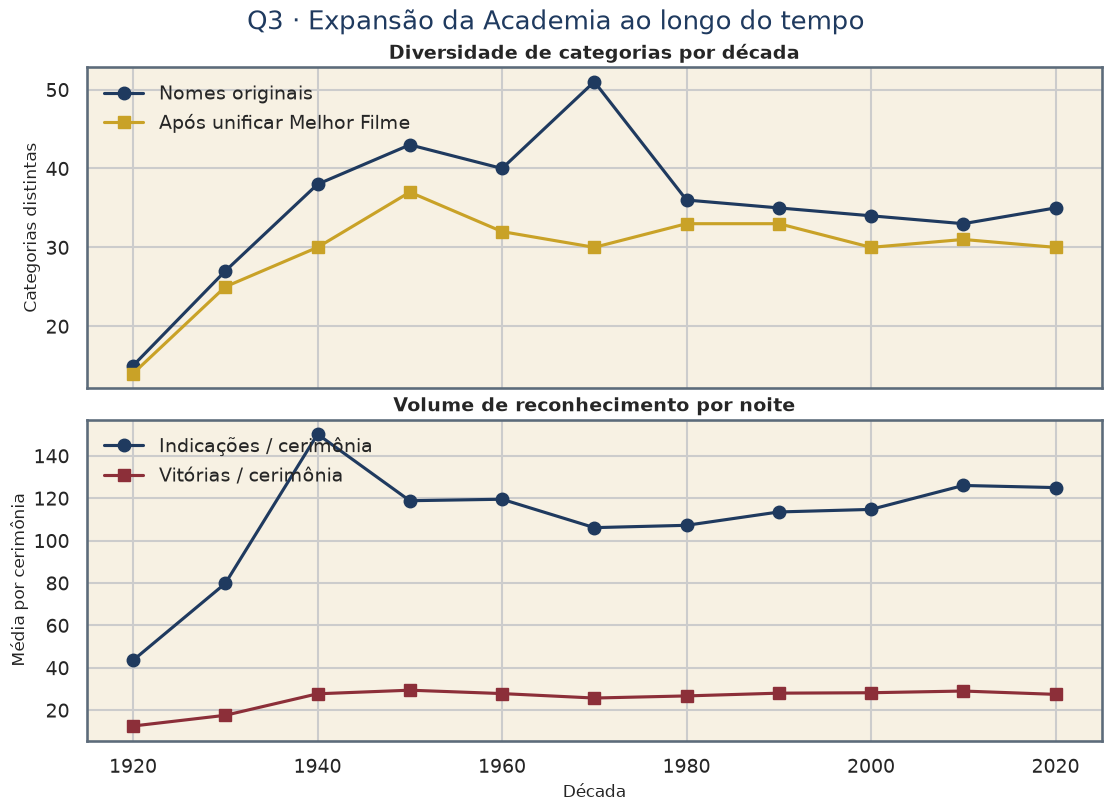

In [9]:
fig = q03_evolucao.plot(q03)
save_fig(fig, q03_evolucao.SLUG)
fig

**Insight.** A Academia do século XXI reconhece mais ofícios do que a dos anos 1930: efeitos, som, animação, documentário. Isso abre frentes de prestígio (e de campanha) que não existiam quando o prêmio era quase só filme, direção e atuação.

## Q4. Volume vs. eficiência de profissionais

Quais profissionais ou entidades possuem o maior histórico de indicações e quem tem a melhor eficiência entre os mais indicados?

Filtro: pelo menos 5 indicações competitivas, excluindo filme internacional (onde `name` é o país). Dois rankings — quem mais é chamado à festa e quem melhor converte o convite em estatueta.

In [10]:
print(q04_eficiencia.QUESTION)
q04 = q04_eficiencia.compute(df)
display(q04.head(15))
q04.sort_values(['win_rate', 'nominations'], ascending=False).head(15)

Quais profissionais ou entidades possuem o maior histórico de indicações e quem tem a melhor eficiência entre os mais indicados?


,name,nominations,wins,first_year,last_year,win_rate
0,Metro-Goldwyn-Mayer,67,12,1928,1968,0.179104
1,Walt Disney,59,22,1932,1969,0.372881
2,John Williams,47,5,1968,2024,0.106383
3,Warner Bros.,43,7,1930,1963,0.162791
4,Alfred Newman,34,7,1939,1971,0.205882
5,Paramount,25,5,1933,1952,0.200000
6,RKO Radio,24,1,1931,1948,0.041667
7,Gordon Hollingshead,23,7,1933,1953,0.304348
8,Edith Head,22,4,1952,1976,0.181818
9,20th Century-Fox,22,3,1938,1969,0.136364


,name,nominations,wins,first_year,last_year,win_rate
190,John Ford,5,4,1936,1953,0.800000
132,John Barry,6,4,1967,1993,0.666667
191,20th Century-Fox/Thomas T. Moulton,5,3,1946,1953,0.600000
192,Daniel Mandell,5,3,1942,1961,0.600000
193,James L. Brooks,5,3,1984,1988,0.600000
194,Leo McCarey,5,3,1938,1953,0.600000
195,Metro-Goldwyn-Mayer/Franklin E. Milton,5,3,1960,1967,0.600000
196,Nick Park,5,3,1991,2010,0.600000
197,Oliver Stone,5,3,1979,1992,0.600000
198,Richard King,5,3,2004,2015,0.600000


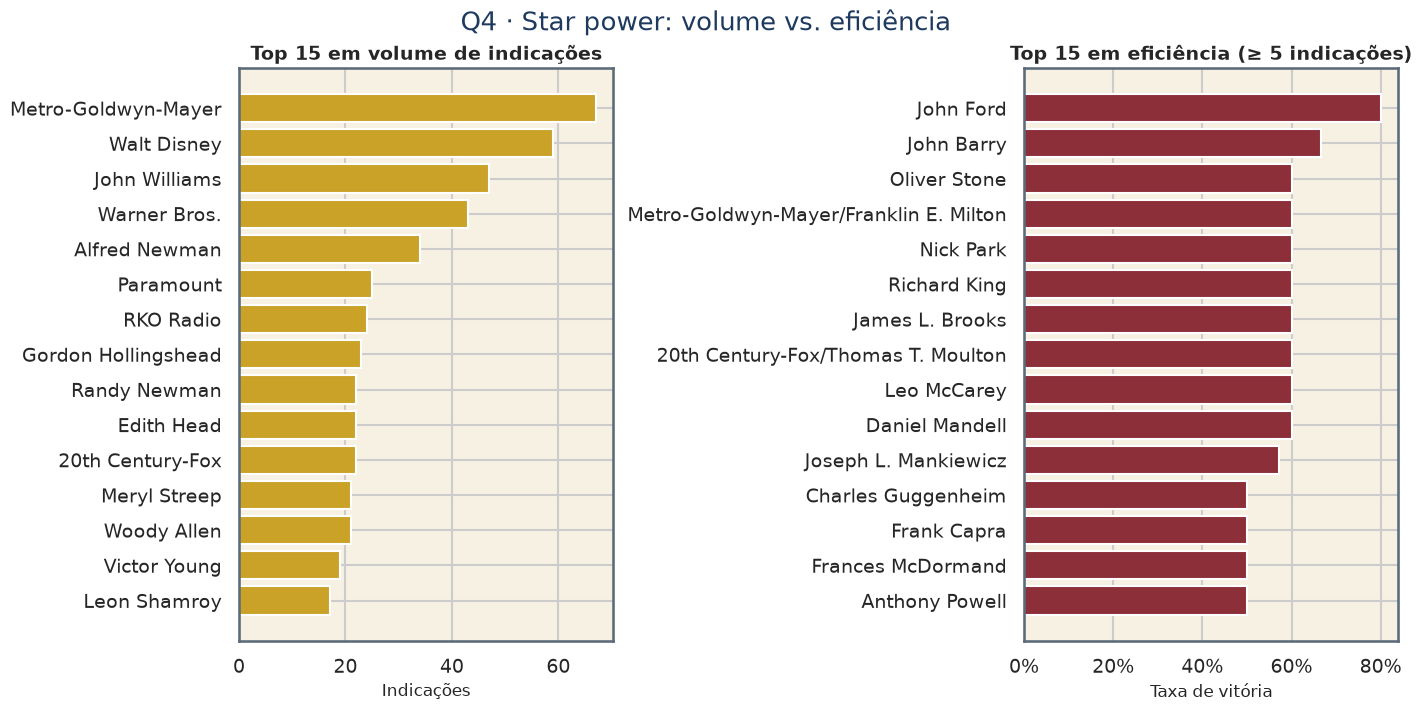

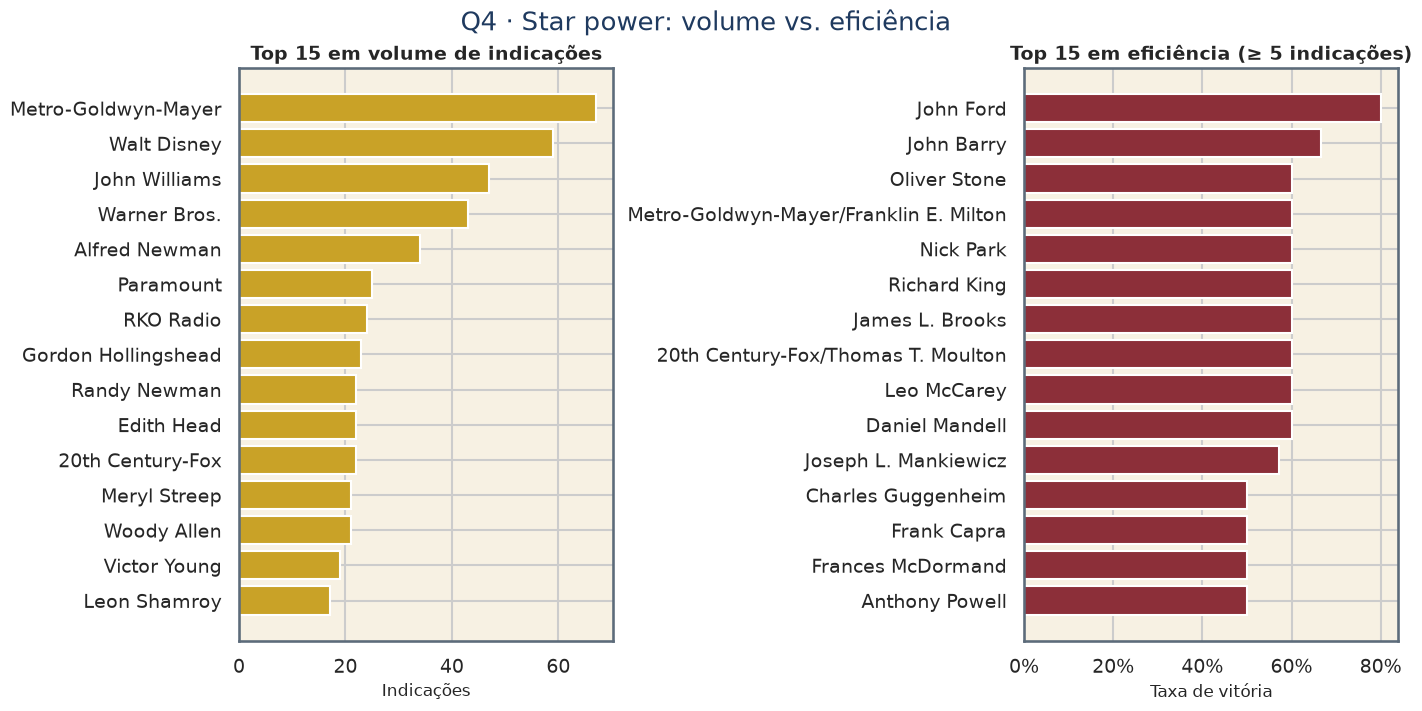

In [11]:
fig = q04_eficiencia.plot(q04)
save_fig(fig, q04_eficiencia.SLUG)
fig

**Insight.** *Star power* compra indicação com mais previsibilidade do que vitória. Contratar o profissional mais indicado aumenta a chance de entrar na cédula; a taxa de conversão dos recordistas costuma ser bem mais baixa do que o marketing de "vencedor do Oscar" sugere. Eficiência e volume não são a mesma lista.

## Q5. Concentração vs. pulverização da noite

Qual é o nível de concentração vs. democratização do Oscar ao longo do tempo: quantos filmes diferentes dividem os prêmios em uma cerimônia?

Por cerimônia: quantos filmes distintos levaram pelo menos uma estatueta competitiva, e que fração dos prêmios ficou com o filme mais premiado (efeito varredura).

In [12]:
print(q05_concentracao.QUESTION)
q05 = q05_concentracao.compute(df)
display(q05.tail(10))
from projeto1_c11.questions.q05_concentracao import decade_means
decade_means(q05)

Qual é o nível de concentração vs. democratização do Oscar ao longo do tempo: quantos filmes diferentes dividem os prêmios em uma cerimônia?


,year_ceremony,n_winning_films,n_awards,max_film_wins,top_film_share,decade,n_winning_films_ma,top_film_share_ma
88,2017,15,24,6,0.250000,2010,15.400000,0.200000
89,2018,15,24,4,0.166667,2010,15.400000,0.200000
90,2019,15,24,4,0.166667,2010,15.200000,0.176087
91,2020,16,24,4,0.166667,2020,15.200000,0.178261
92,2021,15,23,3,0.130435,2020,14.800000,0.205797
93,2022,15,23,6,0.260870,2020,14.400000,0.233333
94,2023,13,23,7,0.304348,2020,14.000000,0.243478
95,2024,13,23,7,0.304348,2020,13.800000,0.265391
96,2025,14,23,5,0.217391,2020,13.500000,0.266522
97,2026,14,25,6,0.240000,2020,13.666667,0.253913


,decade,mean_winning_films,mean_top_film_share,n_ceremonies
0,1920,8.500000,0.171429,2
1,1930,10.777778,0.232562,9
2,1940,16.200000,0.219887,10
3,1950,15.500000,0.250484,10
4,1960,14.100000,0.263940,10
5,1970,13.000000,0.266667,10
6,1980,13.100000,0.257154,10
7,1990,13.800000,0.277108,10
8,2000,14.700000,0.230978,10
9,2010,14.600000,0.207667,10


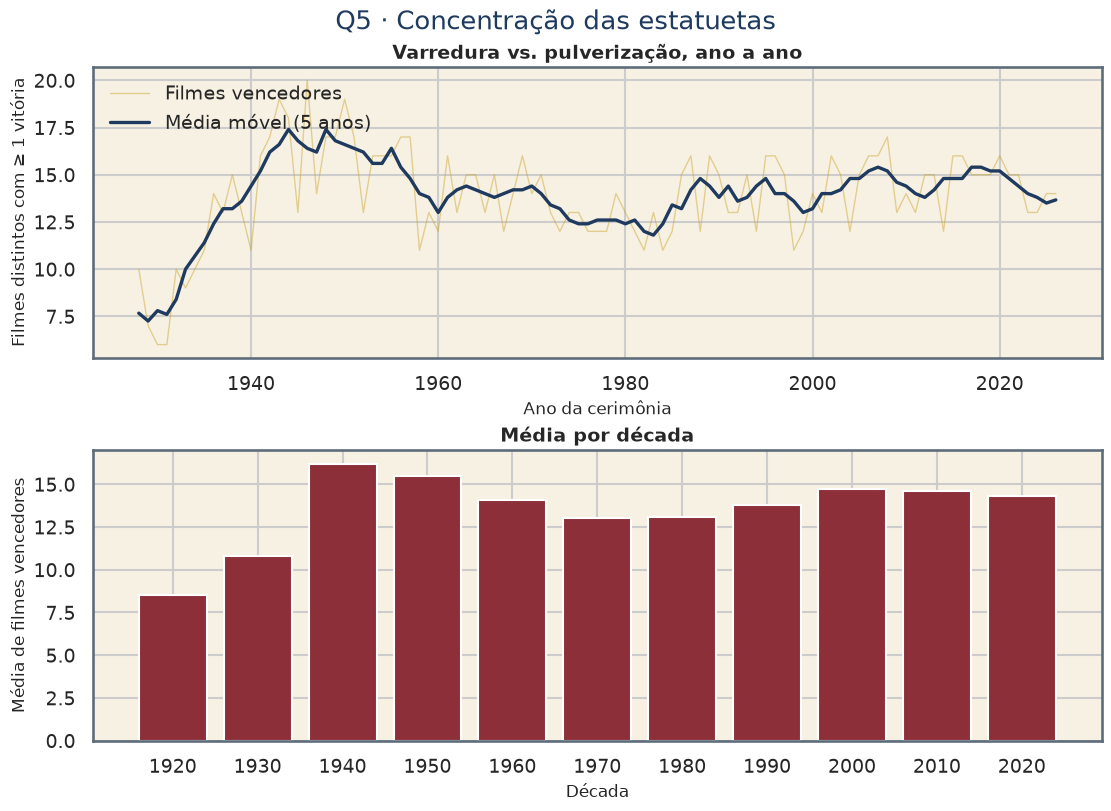

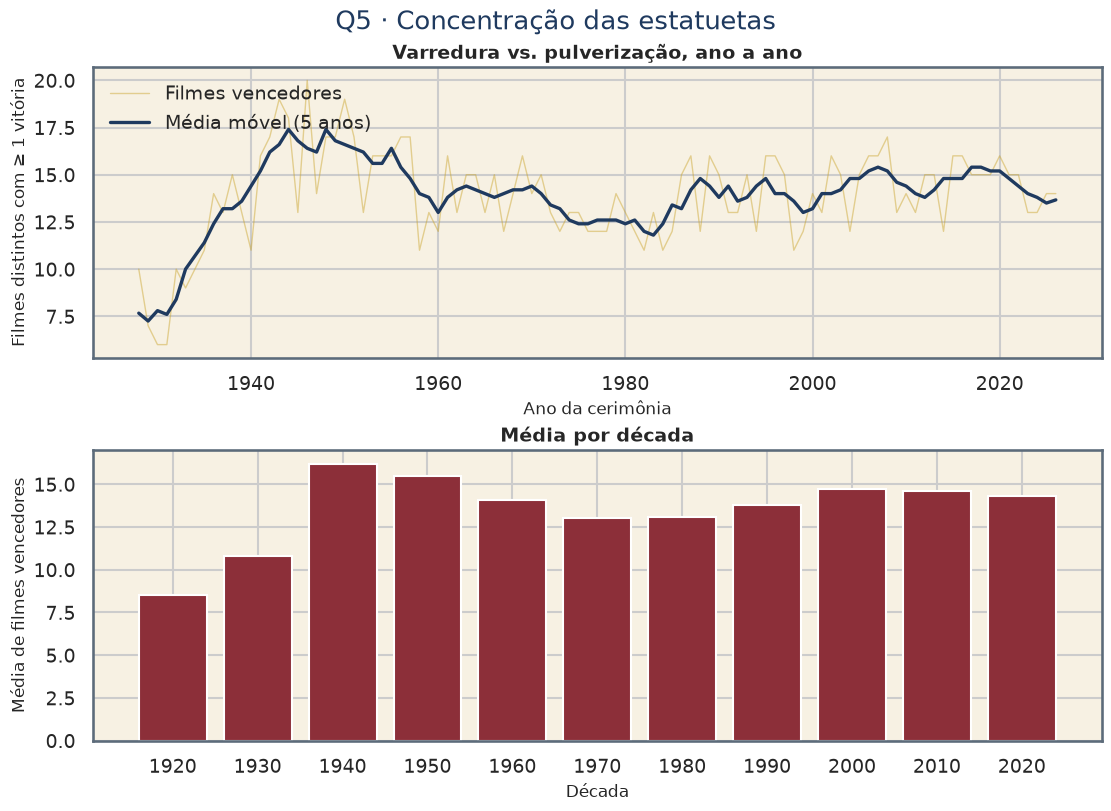

In [13]:
fig = q05_concentracao.plot(q05)
save_fig(fig, q05_concentracao.SLUG)
fig

**Insight.** Noites de varredura (um filme levando fatia grande do quadro) aumentam o risco para concorrentes: o prestígio e a narrativa da imprensa ficam monopolizados. Décadas mais pulverizadas abrem espaço para independentes e *streamings* saírem com 1–2 estatuetas e ainda assim venderem o selo Oscar.

## Parte II — Perguntas complementares (slides completos)

## Q6. Persistência premiada e os maiores injustiçados

Quais profissionais acumularam o maior número de indicações antes da primeira estatueta — e quem nunca venceu?

**Como lemos:** à esquerda, derrotas estritamente anteriores ao ano da primeira vitória. À direita, o ranking de quem saiu do século sem nenhuma estatueta competitiva (honorários e filme internacional excluídos).

In [14]:
print(q06_persistencia.QUESTION)
q06 = q06_persistencia.compute(df)
display(q06_persistencia.late_champions(q06))
display(q06_persistencia.never_won(q06))


Quais são os casos de persistência premiada — profissionais que mais acumularam indicações antes da primeira estatueta — e quem são os maiores injustiçados que nunca venceram?


,name,nominations,wins,first_year,first_win_year,losses_before_first_win,status
31,Elmer Bernstein,10,1,1956,1968,6,campeao_tardio
30,Alexandre Desplat,12,2,2007,2015,6,campeao_tardio
29,Miklos Rozsa,14,2,1941,1946,6,campeao_tardio
28,Warner Bros.,43,7,1930,1937,6,campeao_tardio
21,Geraldine Page,8,1,1954,1986,7,campeao_tardio
20,Paul Newman,10,1,1959,1987,7,campeao_tardio
19,Franz Waxman,12,2,1939,1951,7,campeao_tardio
15,20th Century-Fox/E. H. Hansen,9,1,1936,1945,8,campeao_tardio
14,Paul Thomas Anderson,10,2,1998,2026,8,campeao_tardio
13,Jerry Goldsmith,17,1,1963,1977,8,campeao_tardio


,name,nominations,wins,first_year,first_win_year,losses_before_first_win,status
23,George Pal,7,0,1942,<NA>,7,sem_vitoria
24,James Newton Howard,7,0,1992,<NA>,7,sem_vitoria
25,Mike Leigh,7,0,1997,<NA>,7,sem_vitoria
22,Bill Thomas,7,0,1961,<NA>,7,sem_vitoria
17,Peter O'Toole,8,0,1963,<NA>,8,sem_vitoria
16,Glenn Close,8,0,1983,<NA>,8,sem_vitoria
18,Robert Emmett Dolan,8,0,1942,<NA>,8,sem_vitoria
11,Ingmar Bergman,9,0,1960,<NA>,9,sem_vitoria
12,Stanley Kramer,9,0,1953,<NA>,9,sem_vitoria
8,Paramount/Loren L. Ryder,10,0,1938,<NA>,10,sem_vitoria


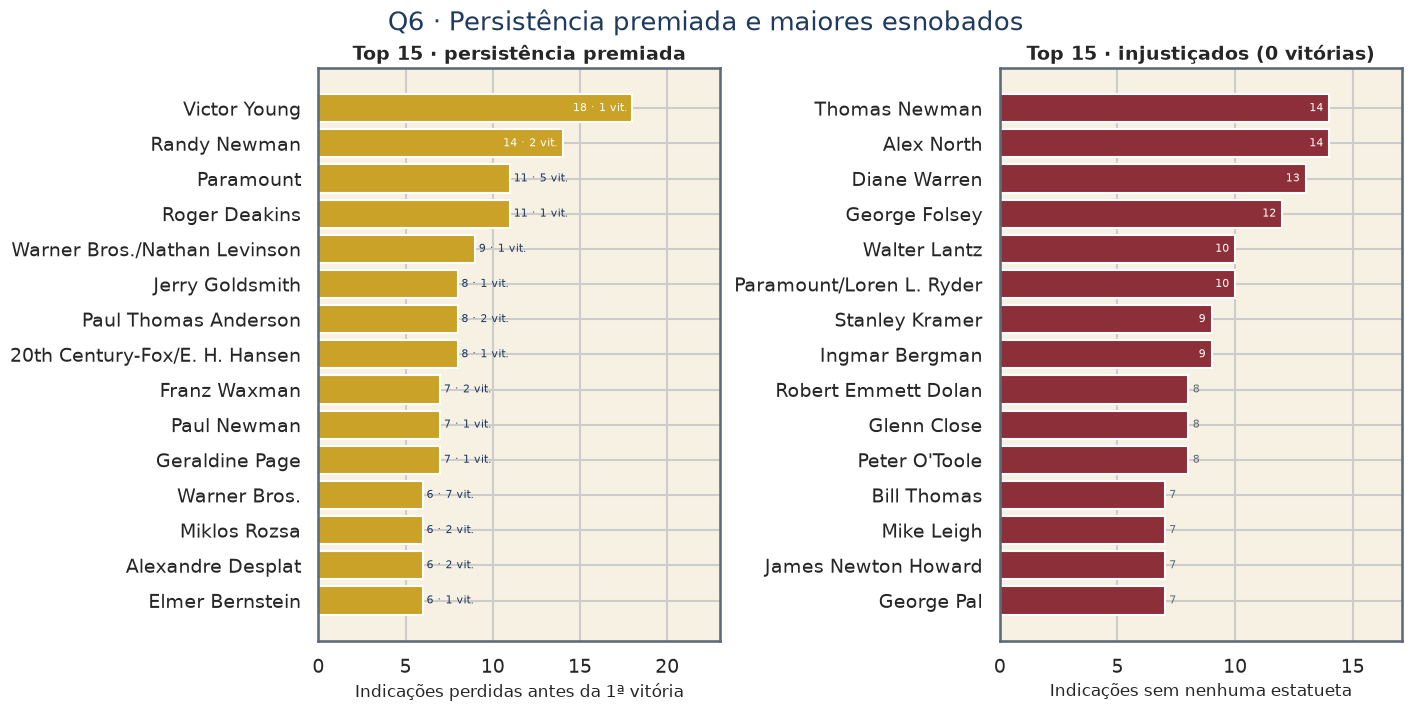

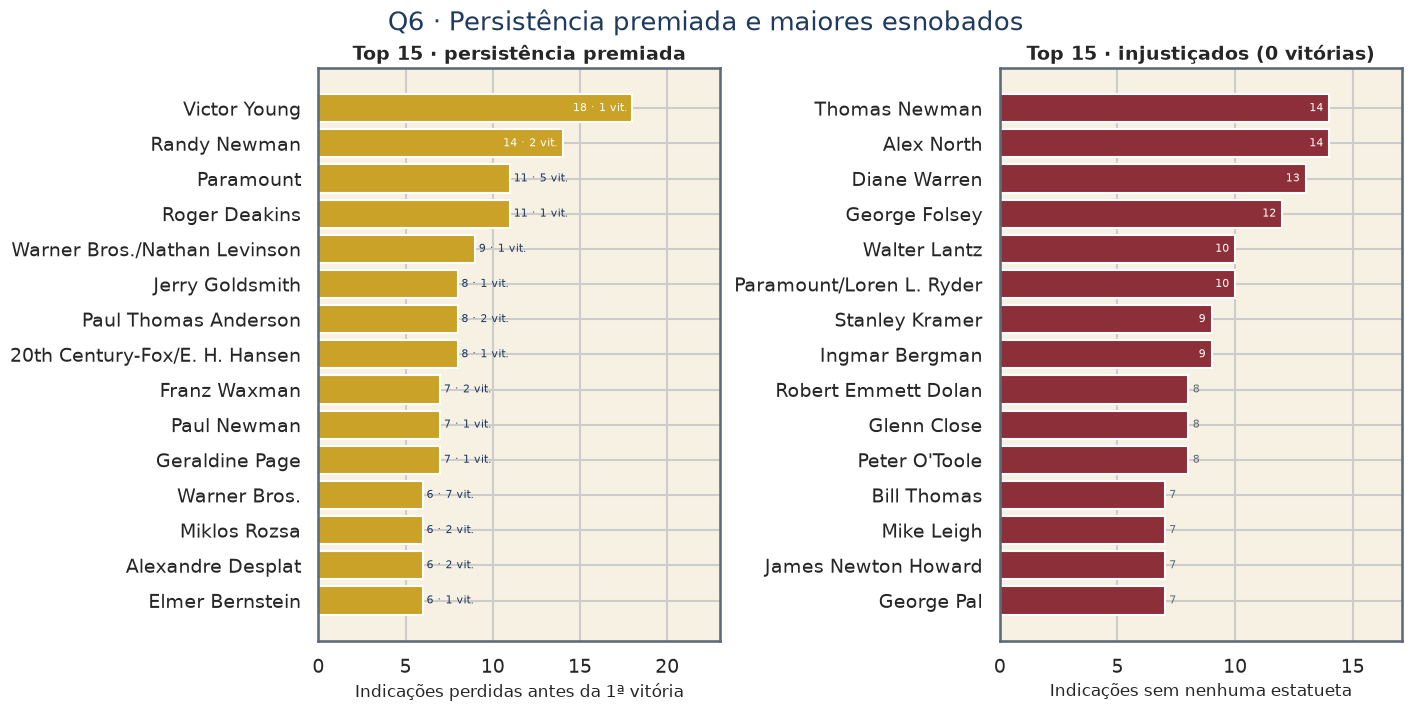

In [15]:
fig = q06_persistencia.plot(q06)
save_fig(fig, q06_persistencia.SLUG)
fig


**Insight.** A Academia reconhece tarde: Victor Young levou 18 indicações até a primeira (e única) estatueta; Randy Newman, 14; Roger Deakins, 11. Do outro lado, Thomas Newman e Alex North chegaram a 14 convites sem nunca subir ao palco — o selo "indicado ao Oscar" vira carreira, a foto da estatueta não. Contratar o eterno finalista compra campanha; não compra o discurso.

## Q7. Recordistas das quatro categorias de atuação

Qual a evolução e representatividade de Ator/Atriz principal e coadjuvante — quem são os recordistas de indicações e vitórias?

Filtro: as quatro categorias canônicas de atuação. O painel da esquerda empilha vitórias sobre o volume de indicações; o da direita ordena quem mais levou a estatueta.

In [16]:
print(q07_atuacao.QUESTION)
q07 = q07_atuacao.compute(df)
display(q07.head(15))
display(q07.sort_values(["wins", "nominations"], ascending=False).head(15))
q07_atuacao.decade_breakdown(df).head(12)


Qual a evolução e representatividade das categorias de atuação (Ator/Atriz Principal e Coadjuvante) — quem são os recordistas de indicações e vitórias nessas quatro categorias?


,name,nominations,wins,leading_nominations,supporting_nominations,first_year,last_year,win_rate
0,Meryl Streep,21,3,17,4,1979,2018,0.142857
1,Katharine Hepburn,12,4,12,0,1933,1982,0.333333
2,Jack Nicholson,12,3,8,4,1970,2003,0.250000
3,Bette Davis,11,2,11,0,1935,1963,0.181818
4,Denzel Washington,9,2,7,2,1988,2022,0.222222
5,Spencer Tracy,9,2,9,0,1937,1968,0.222222
6,Al Pacino,9,1,5,4,1973,2020,0.111111
7,Laurence Olivier,9,1,8,1,1940,1979,0.111111
8,Paul Newman,9,1,8,1,1959,2003,0.111111
9,Cate Blanchett,8,2,5,3,1999,2023,0.250000


,name,nominations,wins,leading_nominations,supporting_nominations,first_year,last_year,win_rate
1,Katharine Hepburn,12,4,12,0,1933,1982,0.333333
0,Meryl Streep,21,3,17,4,1979,2018,0.142857
2,Jack Nicholson,12,3,8,4,1970,2003,0.250000
17,Ingrid Bergman,7,3,6,1,1944,1979,0.428571
26,Frances McDormand,6,3,3,3,1989,2021,0.500000
27,Sean Penn,6,3,5,1,1996,2026,0.500000
66,Janet Gaynor,4,3,4,0,1928,1938,0.750000
67,Walter Brennan,4,3,0,4,1937,1942,0.750000
3,Bette Davis,11,2,11,0,1935,1963,0.181818
4,Denzel Washington,9,2,7,2,1988,2022,0.222222


,decade,category_canon,n_nominations,n_wins
0,1920,ACTOR IN A LEADING ROLE,9,3
1,1920,ACTRESS IN A LEADING ROLE,11,4
2,1930,ACTOR IN A LEADING ROLE,42,10
3,1930,ACTOR IN A SUPPORTING ROLE,15,3
4,1930,ACTRESS IN A LEADING ROLE,43,9
5,1930,ACTRESS IN A SUPPORTING ROLE,15,3
6,1940,ACTOR IN A LEADING ROLE,50,10
7,1940,ACTOR IN A SUPPORTING ROLE,50,10
8,1940,ACTRESS IN A LEADING ROLE,50,10
9,1940,ACTRESS IN A SUPPORTING ROLE,50,10


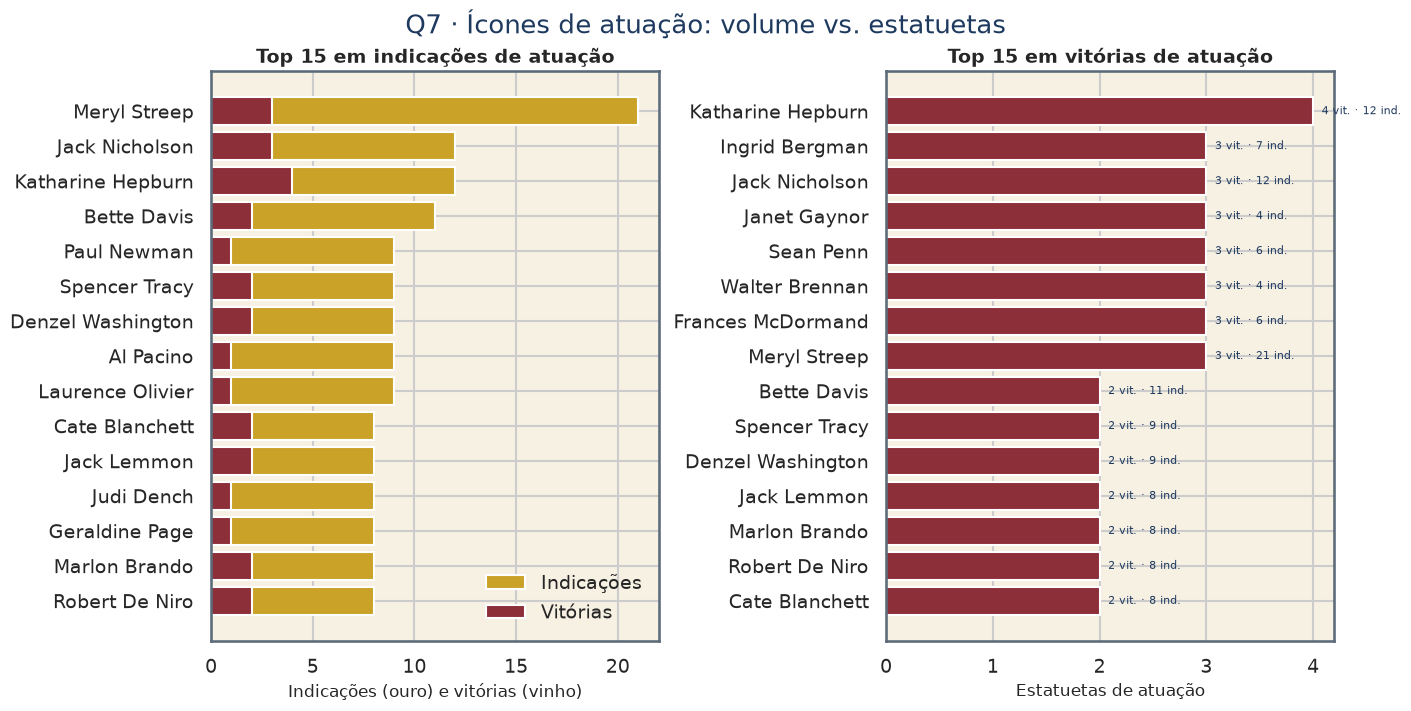

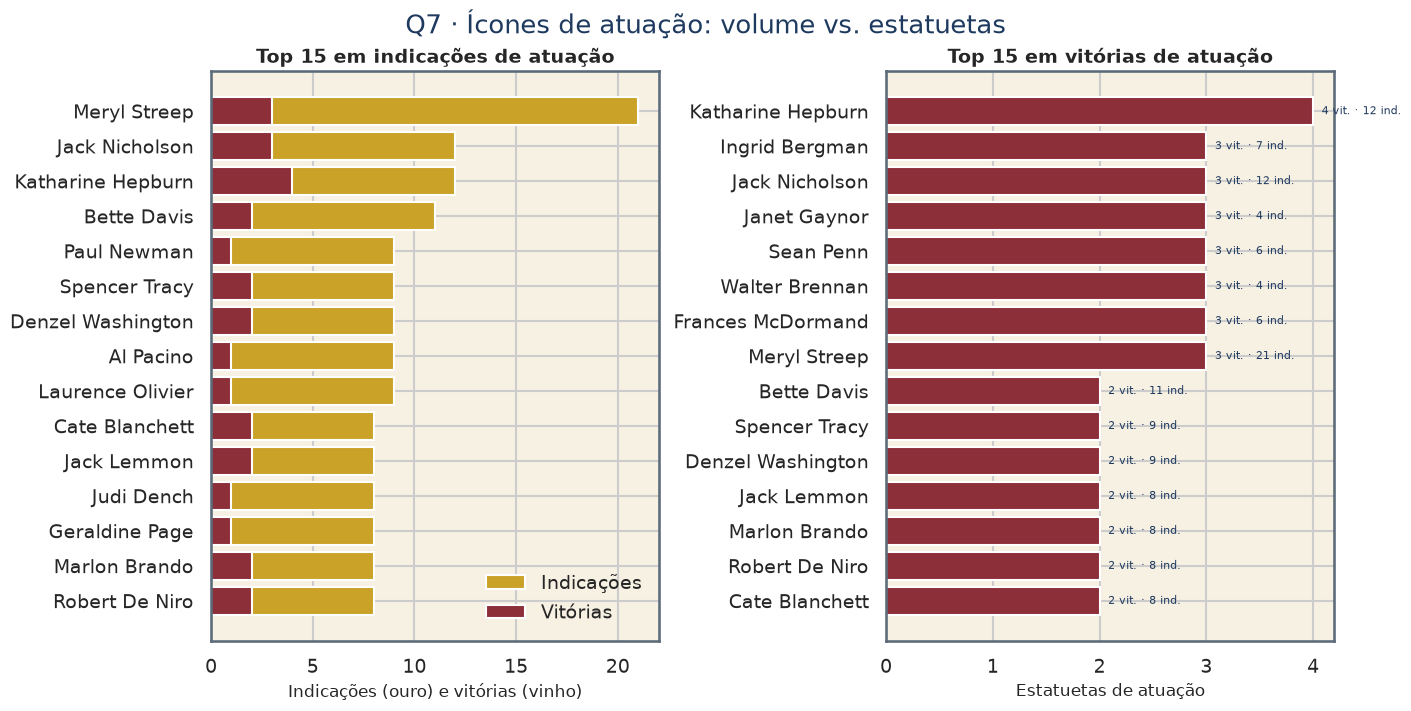

In [17]:
fig = q07_atuacao.plot(q07)
save_fig(fig, q07_atuacao.SLUG)
fig


**Insight.** Meryl Streep (21 indicações, 3 vitórias) é o volume; Katharine Hepburn (12/4) é a eficiência. Coadjuvante só entra no quadro na década de 1930 — a Academia demorou uma década para reconhecer o elenco além do protagonista. Para o elenco, o nome no cartaz agrega o selo de campanha; a taxa de conversão dos recordistas continua baixa.

## Q8. Nomenclatura histórica das categorias

Como os nomes das categorias mudaram e o que isso diz sobre a modernização da indústria?

Cada segmento é um nome original (`category`) dentro da família canônica. Melhor Filme já teve cinco rótulos; atuação principal ganhou "in a Leading Role" em 1977; filme internacional deixou de ser "Foreign Language" em 2020.

In [18]:
print(q08_nomenclatura.QUESTION)
q08 = q08_nomenclatura.compute(df)
renamed = q08_nomenclatura.renamed_families(q08)
print(f"famílias que mudaram de nome={renamed['category_canon'].nunique()}")
q08.loc[q08["category_canon"].isin(q08_nomenclatura.NOMENCLATURE_FAMILIES)]


Como a nomenclatura das categorias mudou ao longo da história do Oscar e o que isso revela sobre a modernização da indústria?
famílias que mudaram de nome=19


,category_canon,category,first_year,last_year,n_ceremonies,n_entries,n_distinct_names
0,ACTOR IN A LEADING ROLE,ACTOR,1928,1976,48,236,2
1,ACTOR IN A LEADING ROLE,ACTOR IN A LEADING ROLE,1977,2026,50,250,2
3,ACTRESS IN A LEADING ROLE,ACTRESS,1928,1976,48,239,2
4,ACTRESS IN A LEADING ROLE,ACTRESS IN A LEADING ROLE,1977,2026,50,250,2
7,ART DIRECTION,ART DIRECTION,1928,2012,59,309,2
8,ART DIRECTION,PRODUCTION DESIGN,2013,2026,14,70,2
13,BEST PICTURE,OUTSTANDING PICTURE,1928,1929,2,8,5
14,BEST PICTURE,OUTSTANDING PRODUCTION,1930,1941,11,102,5
15,BEST PICTURE,OUTSTANDING MOTION PICTURE,1942,1944,3,30,5
16,BEST PICTURE,BEST MOTION PICTURE,1945,1962,18,90,5


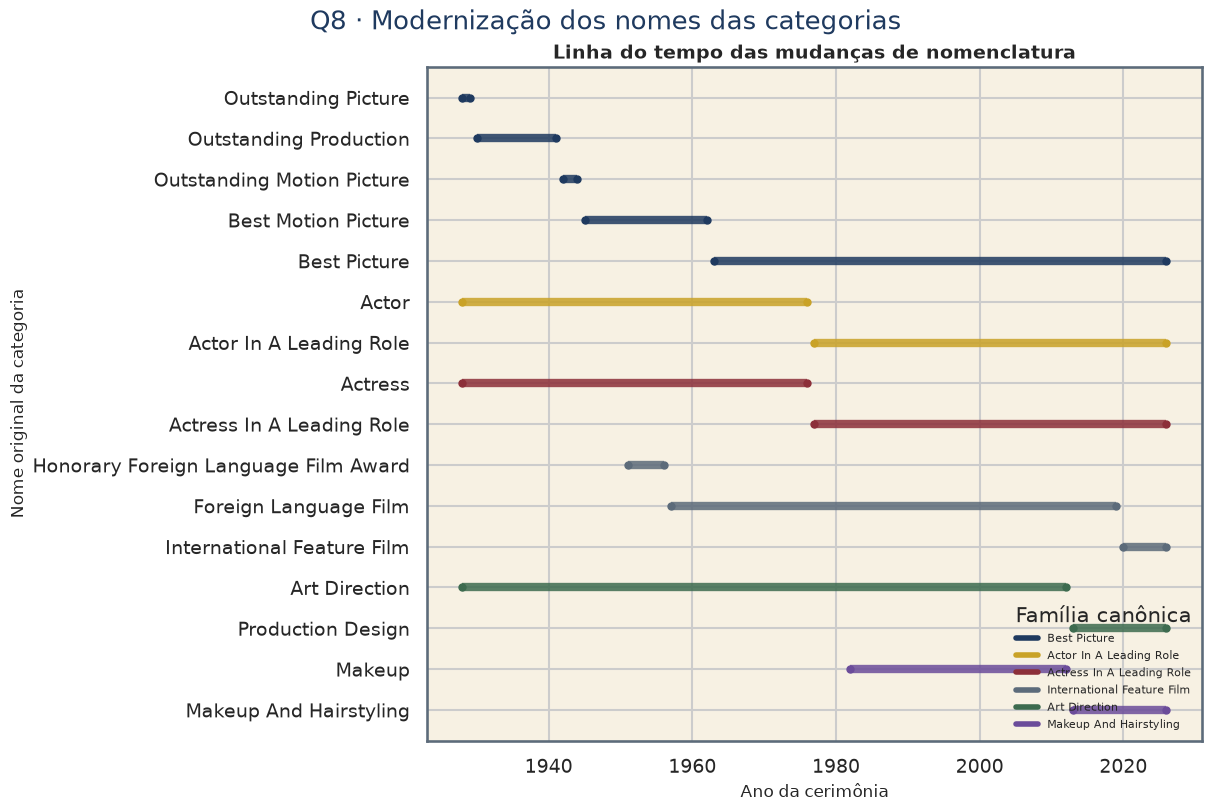

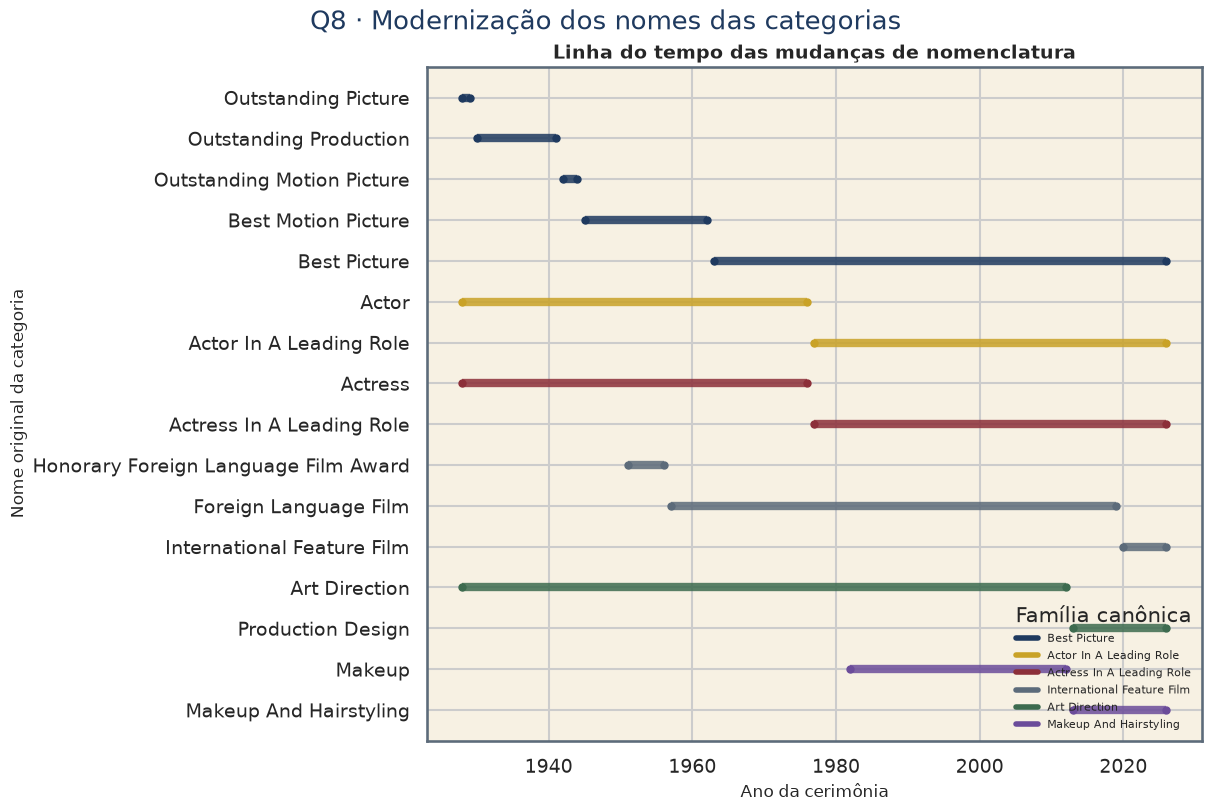

In [19]:
fig = q08_nomenclatura.plot(q08)
save_fig(fig, q08_nomenclatura.SLUG)
fig


**Insight.** Trocar o nome é política industrial: *Outstanding Production* vira *Best Picture*, *Foreign Language Film* vira *International Feature Film*, *Art Direction* vira *Production Design*. Sem unificar esses aliases (desafio nº 1 da Descoberta), qualquer série temporal parte o século no meio — exatamente o que a linha de "nomes originais" da Q3 já denunciava.

## Q9. Janela de elegibilidade: `year_film` vs. `year_ceremony`

Existe diferença histórica entre o ano do filme e o ano da cerimônia — pandemias, primeiros anos da Academia, mudanças de regulamento?

O CSV do Kaggle padroniza `year_film = year_ceremony - 1` em **todas** as linhas. O sinal real está no calendário das edições: não houve cerimônia em 1934, e o offset `ano − 1927 − edição` salta de 0 para 1 a partir de 1935.

In [20]:
print(q09_elegibilidade.QUESTION)
q09 = q09_elegibilidade.compute(df)
print("lag único:", sorted(q09["lag_film_ceremony"].dropna().unique().tolist()))
display(q09_elegibilidade.calendar_anomalies(q09))
q09.loc[q09["year_ceremony"].isin([1928, 1933, 1935, 2021])]


Existe diferença histórica no comportamento de year_film vs. year_ceremony (janelas de elegibilidade atípicas, pandemia ou os primeiros anos da Academia)?
lag único: [1]


,ceremony,year_ceremony,year_film,n_nominations,n_categories,lag_film_ceremony,calendar_gap,ceremony_offset
6,7,1935,1934,64,17,1,2.0,1


,ceremony,year_ceremony,year_film,n_nominations,n_categories,lag_film_ceremony,calendar_gap,ceremony_offset
0,1,1928,1927,41,13,1,NaN,0
5,6,1933,1932,62,13,1,1.0,0
6,7,1935,1934,64,17,1,2.0,1
92,93,2021,2020,120,24,1,1.0,1


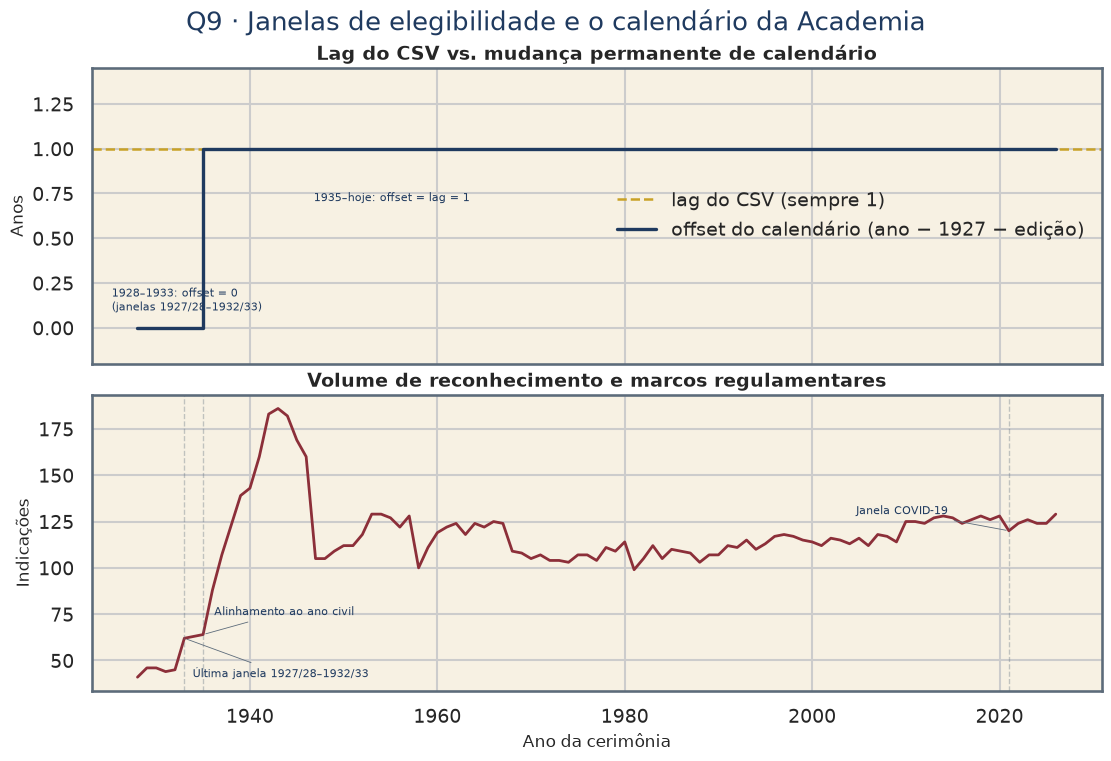

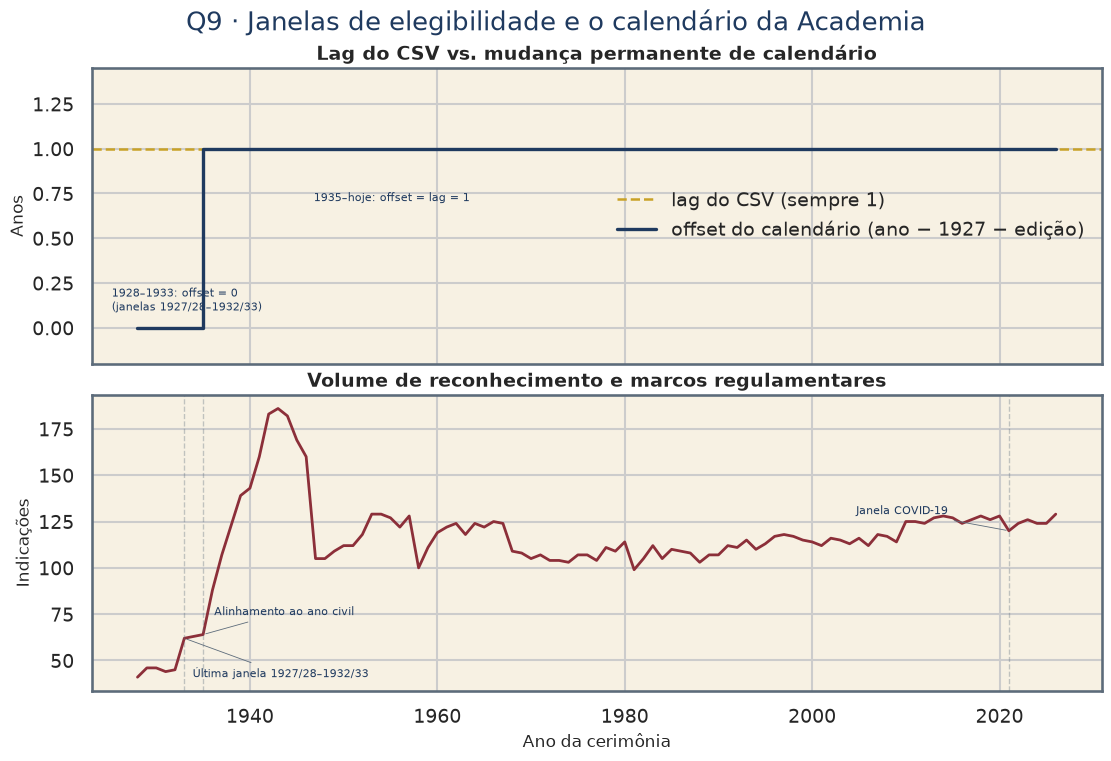

In [21]:
fig = q09_elegibilidade.plot(q09)
save_fig(fig, q09_elegibilidade.SLUG)
fig


**Insight.** O dataset **não** registra a janela estendida da pandemia em `year_film` (a cerimônia de 2021 continua com lag 1). Quem for modelar elegibilidade precisa do calendário da edição, não da coluna de lag: o único furo estatístico no século é 1934, quando a Academia abandonou as janelas 1927/28–1932/33 e alinhou o prêmio ao ano civil.

## Q10. Concorrentes por categoria e a cédula de Melhor Filme

Qual a proporção média de concorrentes por categoria — em especial a expansão de 5 para até 10 indicados em Melhor Filme a partir de 2010 — e como isso mudou a probabilidade matemática de vitória?

In [22]:
print(q10_concorrentes.QUESTION)
q10 = q10_concorrentes.compute(df)
display(q10.loc[q10["year_ceremony"].isin([1944, 1945, 2009, 2010, 2021, 2022, 2026])])
from projeto1_c11.questions.q10_concorrentes import category_competition_by_decade
category_competition_by_decade(df)


Qual a proporção média de concorrentes por categoria ao longo das décadas (especialmente a expansão de 5 para até 10 indicados em Melhor Filme a partir de 2010)? Como isso alterou a probabilidade matemática de vitória?


,year_ceremony,n_nominees,n_winners,win_prob,decade,other_mean_nominees,other_win_prob
15,1944,10,1,0.100,1940,7.391304,0.135294
16,1945,5,1,0.200,1940,7.000000,0.142857
80,2009,5,1,0.200,2000,4.608696,0.216981
81,2010,10,1,0.100,2010,4.826087,0.207207
92,2021,8,1,0.125,2020,5.000000,0.200000
93,2022,10,1,0.100,2020,5.000000,0.200000
97,2026,10,1,0.100,2020,5.000000,0.200000


,decade,mean_nominees,median_nominees,n_category_years
0,1920,4.473684,4.0,19
1,1930,5.225564,5.0,133
2,1940,6.293103,5.0,232
3,1950,4.547619,5.0,252
4,1960,4.686747,5.0,249
5,1970,4.736111,5.0,216
6,1980,4.543860,5.0,228
7,1990,4.583333,5.0,240
8,2000,4.510121,5.0,247
9,2010,4.963265,5.0,245


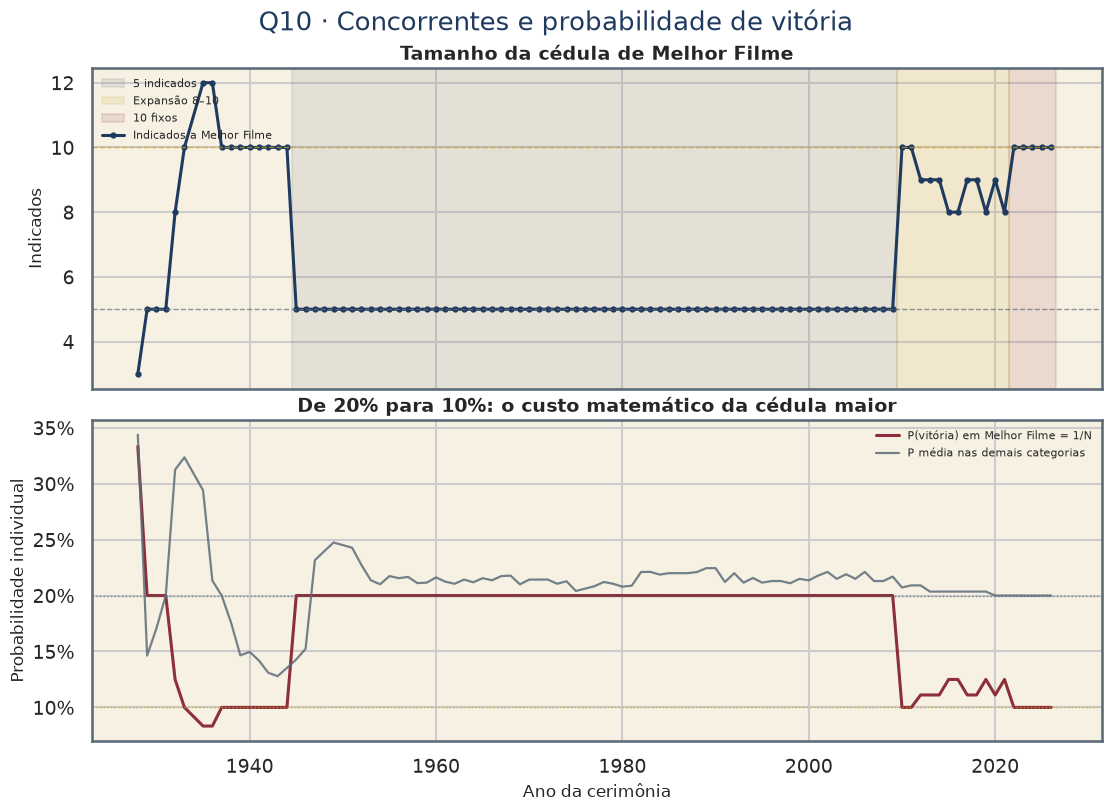

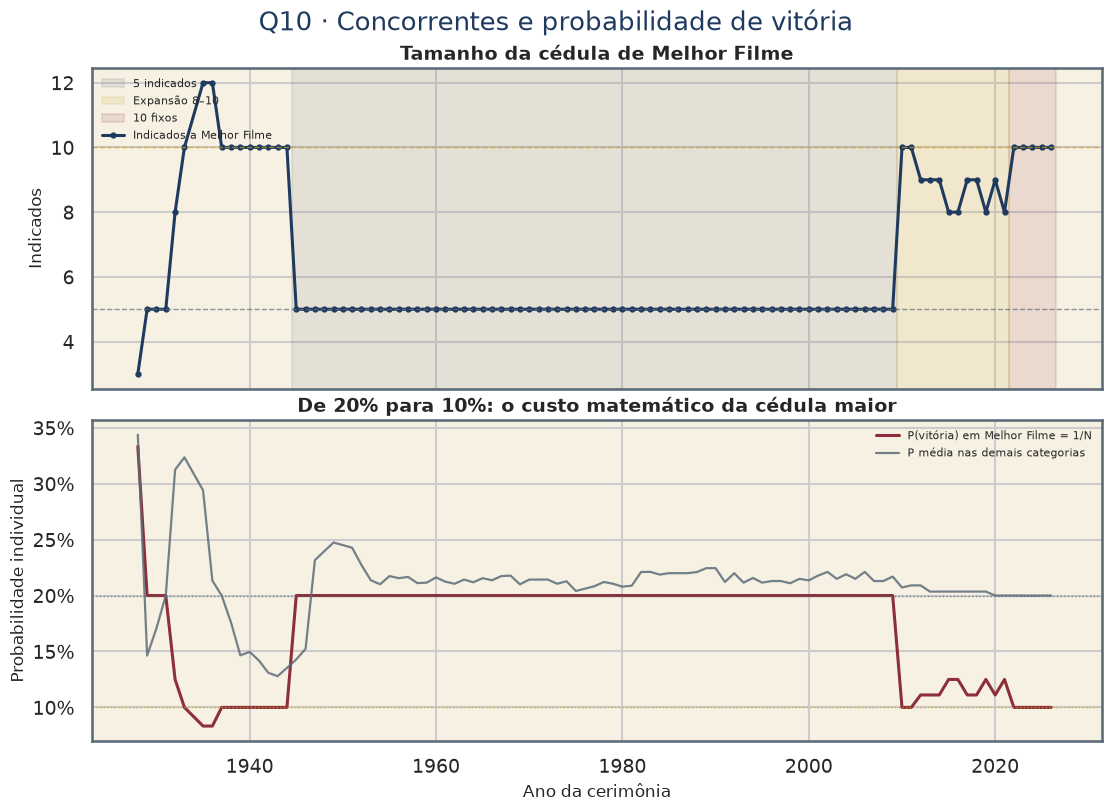

In [23]:
fig = q10_concorrentes.plot(q10)
save_fig(fig, q10_concorrentes.SLUG)
fig


**Insight.** De 1945 a 2009, Melhor Filme era um jogo de 1 em 5 (20%). Em 2010 a cédula dobra e a probabilidade individual cai para 10%; de 2022 em diante ela fica fixa em 10 indicados. As demais categorias continuam em torno de 5 nomes (~20%). Para o estúdio, a cédula maior é marketing ("indicado a Melhor Filme") barateado — e vitória matemática mais rara.